<a href="https://colab.research.google.com/github/HamzaEric/caltech101-transfer-learning/blob/main/Notebooks/Transfer_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import matplotlib.pyplot as plt
import numpy as np
import os
import json
import pandas as pd
from pathlib import Path
import zipfile
from PIL import Image
import random
from torch.utils.data import DataLoader
import shutil
from torchvision import models
from torchsummary import summary
import math
import torch.nn.functional as F
import requests

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[info] Using device: {device}")

[info] Using device: cpu


# Dataset Overview

Pictures of objects belonging to 101 categories. About 40 to 800 images per category. Most categories have about 50 images. Collected in September 2003 by Fei-Fei Li, Marco Andreetto, and Marc'Aurelio Ranzato. The size of each image is roughly 300 x 200 pixels.

Li, F.-F., Andreeto, M., Ranzato, M., & Perona, P. (2022). Caltech 101 (Version 1.0) [Dataset]. CaltechDATA. https://doi.org/10.22002/D1.20086

In [4]:
zip_path = '/content/drive/MyDrive/caltech-101.zip'
extract_path = '/content'


os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
    print(f"Successfully extracted all files to: {extract_path}")

Successfully extracted all files to: /content


In [5]:
!tar -xzf /content/caltech-101/101_ObjectCategories.tar.gz -C /content/caltech-101/

In [7]:
data_dir = '/content/caltech-101/101_ObjectCategories'

class_names = sorted([
    d for d in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, d))
])

class_to_idx = {class_name: idx for idx, class_name in enumerate(class_names)}
idx_to_class = {idx: class_name for idx, class_name in enumerate(class_names)}

print(f"Total Classes Found: {len(class_names)}")
print(f"First 5 classes: {class_names[:5]}")

Total Classes Found: 102
First 5 classes: ['BACKGROUND_Google', 'Faces', 'Faces_easy', 'Leopards', 'Motorbikes']


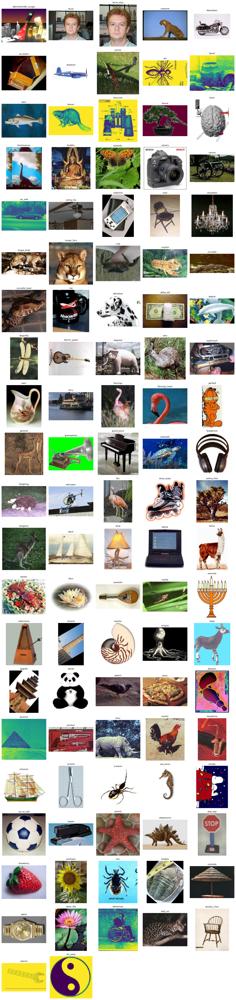

In [10]:
cols = 5
total_classes = len(class_names)
rows = (total_classes // cols) + (1 if total_classes % cols != 0 else 0)

plt.figure(figsize=(15, rows * 3))

for i, class_name in enumerate(class_names):
    class_path = os.path.join(data_dir, class_name)
    images = [f for f in os.listdir(class_path) if f.lower().endswith(('png', 'jpg', 'jpeg'))]

    if images:
        # Load the first image in the folder
        img_path = os.path.join(class_path, images[0])
        img = Image.open(img_path)

        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(class_name, fontsize=9)
        plt.axis('off')

plt.tight_layout()
plt.show()

Top 5 largest classes:
               Class  Count
6          airplanes    800
4         Motorbikes    798
0  BACKGROUND_Google    467
1              Faces    435
2         Faces_easy    435

Top 5 smallest classes:
           Class  Count
44      garfield     34
98      wild_cat     34
12     binocular     33
65     metronome     32
53  inline_skate     31


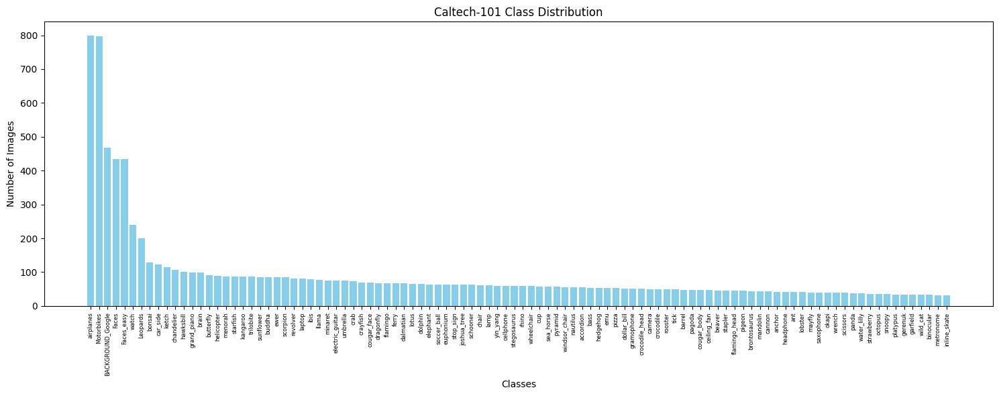

In [11]:
class_counts = {}
for class_name in sorted(os.listdir(data_dir)):
    class_path = os.path.join(data_dir, class_name)
    if os.path.isdir(class_path):
        images = [f for f in os.listdir(class_path) if f.lower().endswith(('png', 'jpg', 'jpeg'))]
        class_counts[class_name] = len(images)

# Convert to a DataFrame for easy analysis
df_counts = pd.DataFrame(list(class_counts.items()), columns=['Class', 'Count'])
df_counts = df_counts.sort_values(by='Count', ascending=False)

print("Top 5 largest classes:")
print(df_counts.head())

print("\nTop 5 smallest classes:")
print(df_counts.tail())

# Plot the distribution
plt.figure(figsize=(15, 6))
plt.bar(df_counts['Class'], df_counts['Count'], color='skyblue')
plt.xticks(rotation=90, fontsize=6)
plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.title("Caltech-101 Class Distribution")
plt.tight_layout()
plt.show()

In [12]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Define the preprocessing pipeline
transform = transforms.Compose([
    transforms.Resize(128),
    transforms.CenterCrop(128),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

print("[info] Transformation pipeline ready.")

[info] Transformation pipeline ready.


In [15]:
source_dir = Path('/content/caltech-101/101_ObjectCategories')
output_dir = Path('/content/caltech-splits')

# Split ratios
train_ratio = 0.70
val_ratio = 0.15


random.seed(42)  # For reproducible splits

for class_folder in source_dir.iterdir():
    if class_folder.is_dir():
        class_name = class_folder.name

        # Get all valid image files
        images = [f for f in class_folder.iterdir() if f.suffix.lower() in ['.jpg', '.jpeg', '.png']]
        random.shuffle(images)

        n_total = len(images)
        n_train = int(n_total * train_ratio)
        n_val = int(n_total * val_ratio)

        train_imgs = images[:n_train]
        val_imgs = images[n_train:n_train + n_val]
        test_imgs = images[n_train + n_val:]

        # Create destination folders
        for split_name, split_imgs in [('train', train_imgs), ('val', val_imgs), ('test', test_imgs)]:
            split_class_dir = output_dir / split_name / class_name
            split_class_dir.mkdir(parents=True, exist_ok=True)

            for img_path in split_imgs:
                shutil.copy(img_path, split_class_dir / img_path.name)

print(f"Dataset successfully split and saved to: {output_dir}")

Dataset successfully split and saved to: /content/caltech-splits


In [16]:
train_dir = '/content/caltech-splits/train'
val_dir = '/content/caltech-splits/val'
test_dir = '/content/caltech-splits/test'

train_dataset = datasets.ImageFolder(root=train_dir, transform=transform)
val_dataset = datasets.ImageFolder(root=val_dir, transform=transform)
test_dataset = datasets.ImageFolder(root=test_dir, transform=transform)

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,       # Shuffle training data
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,      # No need to shuffle validation data
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,      # No need to shuffle test data
    num_workers=2,
    pin_memory=True
)

print(f"Total Training Samples: {len(train_dataset)} ({len(train_loader)} batches)")
print(f"Total Validation Samples: {len(val_dataset)} ({len(val_loader)} batches)")
print(f"Total Test Samples: {len(test_dataset)} ({len(test_loader)} batches)")
print(f"Number of Classes: {len(train_dataset.classes)}")

Total Training Samples: 6352 (199 batches)
Total Validation Samples: 1326 (42 batches)
Total Test Samples: 1466 (46 batches)
Number of Classes: 102


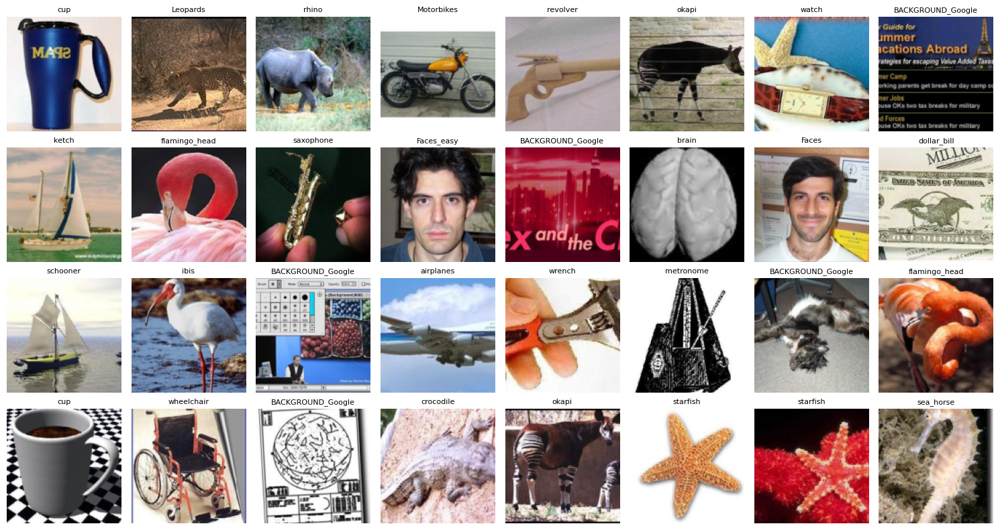

In [18]:
images, labels = next(iter(train_loader))

def denormalize(tensor, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    mean = torch.tensor(mean).view(3, 1, 1)
    std = torch.tensor(std).view(3, 1, 1)
    return tensor * std + mean

fig, axes = plt.subplots(4, 8, figsize=(15, 8))
axes = axes.flatten()

class_names = train_dataset.classes

for i in range(min(32, len(images))):
    img = denormalize(images[i])
    # Permute tensor from (C, H, W) to NumPy (H, W, C) and clip values to [0, 1]
    img = np.clip(img.permute(1, 2, 0).numpy(), 0, 1)

    label_idx = labels[i].item()
    class_name = class_names[label_idx]

    axes[i].imshow(img)
    axes[i].set_title(class_name, fontsize=8)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

**Pretrained CNN**

In [20]:
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

print("[info] Pretrained ResNet-18 loaded successfully.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 159MB/s]


[info] Pretrained ResNet-18 loaded successfully.


In [22]:
summary(model, input_size=(3, 128, 128))

layer_hierarchy = [name for name, _ in model.named_children()]
print("Top-level children:", layer_hierarchy)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 64, 64]           9,408
       BatchNorm2d-2           [-1, 64, 64, 64]             128
              ReLU-3           [-1, 64, 64, 64]               0
         MaxPool2d-4           [-1, 64, 32, 32]               0
            Conv2d-5           [-1, 64, 32, 32]          36,864
       BatchNorm2d-6           [-1, 64, 32, 32]             128
              ReLU-7           [-1, 64, 32, 32]               0
            Conv2d-8           [-1, 64, 32, 32]          36,864
       BatchNorm2d-9           [-1, 64, 32, 32]             128
             ReLU-10           [-1, 64, 32, 32]               0
       BasicBlock-11           [-1, 64, 32, 32]               0
           Conv2d-12           [-1, 64, 32, 32]          36,864
      BatchNorm2d-13           [-1, 64, 32, 32]             128
             ReLU-14           [-1, 64,

In [23]:
print(model)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\n[summary] Total parameters: {total_params:,}")
print(f"[summary] Trainable parameters: {trainable_params:,}")

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

**Freezing Layer and Swapping Classifier**

In [24]:
device = torch.device("cpu")
model = model.to(device)

for p in model.parameters():
    p.requires_grad = False

print("[info] Frozen all backbone parameters.")

[info] Frozen all backbone parameters.


In [26]:
num_classes = len(class_names)


in_features = model.fc.in_features
model.fc = nn.Linear(in_features, num_classes)

# Kaiming initialization (good default for ReLU nets)
nn.init.kaiming_uniform_(model.fc.weight, a=math.sqrt(5))
if model.fc.bias is not None:
    fan_in, _ = nn.init._calculate_fan_in_and_fan_out(model.fc.weight)
    bound = 1 / math.sqrt(fan_in)
    nn.init.uniform_(model.fc.bias, -bound, bound)

model = model.to(device)
model.eval()

print(f"[info] Replaced classifier head: in_features={in_features}, out_features={num_classes}")

[info] Replaced classifier head: in_features=512, out_features=102


In [27]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
trainable_names = [n for n, p in model.named_parameters() if p.requires_grad]

print(f"[summary] Total parameters: {total_params:,}")
print(f"[summary] Trainable parameters (should be only the new head): {trainable_params:,}")
print("[summary] Trainable parameter tensors:")
for n in trainable_names:
    print("  •", n)

# Simple assert (will raise if something other than the new head is trainable)
assert all(n.startswith("fc.") for n in trainable_names), "Unexpected trainable parameters outside the classifier head."
print("[check] Only the classifier head is trainable. Good to proceed.")

[summary] Total parameters: 11,228,838
[summary] Trainable parameters (should be only the new head): 52,326
[summary] Trainable parameter tensors:
  • fc.weight
  • fc.bias
[check] Only the classifier head is trainable. Good to proceed.


### **Zero-Shot Forward Pass and Softmax Predictions**

Now that we have a frozen pretrained feature extractor and a new random classifier head, let’s perform a **zero-shot forward pass**.  
This helps us confirm that the data pipeline and model architecture are working as expected before we begin training.

A **forward pass** means sending input images through the model to compute the output logits — the raw, unnormalized predictions from the final layer.  
  

To interpret these logits, we apply the **softmax** function:

$$
p_i = \frac{e^{z_i}}{\sum_j e^{z_j}}
$$

where $z_i$ is the logit for class $i$ and $p_i$ is its corresponding predicted probability.  
Softmax converts arbitrary logits into a probability distribution that sums to 1 across all classes.

Because our new classifier head is **randomly initialized**, these predictions are effectively **random guesses**.  
However, this step is pedagogically important — it ensures:
- The model receives data of the right shape,
- The forward computation works correctly,
- The output dimensionality matches the number of classes.


In [30]:
# Fetch one mini-batch from the validation loader
images, labels = next(iter(val_loader))
images, labels = images.to(device), labels.to(device)

# Run through the frozen model (no grad tracking)
with torch.no_grad():
    logits = model(images)
    probs = F.softmax(logits, dim=1)

print(f"[check] Logits shape: {logits.shape}")
print(f"[check] Probabilities shape: {probs.shape}")

[check] Logits shape: torch.Size([32, 102])
[check] Probabilities shape: torch.Size([32, 102])


**Inspect Predictions For A Few Samples**

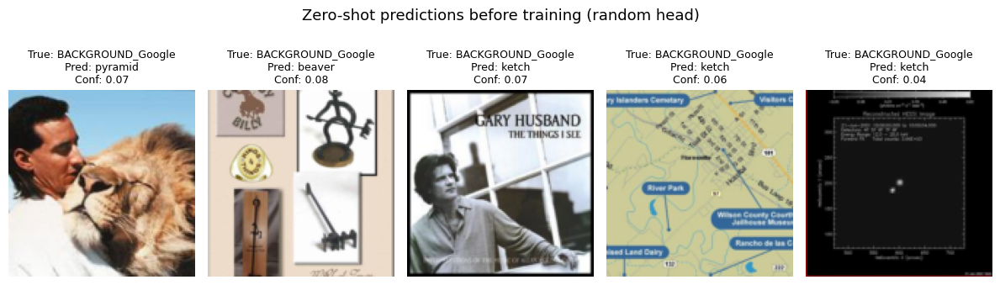

In [32]:
idxs = np.random.choice(len(images), size=5, replace=False)

plt.figure(figsize=(12, 4))
for i, idx in enumerate(idxs):
    img = images[idx].cpu()
    label = labels[idx].item()
    pred_class = torch.argmax(probs[idx]).item()
    confidence = probs[idx][pred_class].item()

    # Unnormalize image for display
    img_disp = img.clone()
    for c, (m, s) in enumerate(zip(IMAGENET_MEAN, IMAGENET_STD)):
        img_disp[c] = img_disp[c] * s + m

    plt.subplot(1, 5, i + 1)
    plt.imshow(img_disp.permute(1, 2, 0).clamp(0, 1))
    plt.axis("off")
    plt.title(
        f"True: {train_dataset.classes[label]}\nPred: {train_dataset.classes[pred_class]}\nConf: {confidence:.2f}",
        fontsize=9,
    )

plt.suptitle("Zero-shot predictions before training (random head)", fontsize=13)
plt.tight_layout()
plt.show()

### **Pretrained Models Learning**

Convolutional neural networks (CNNs) build a **hierarchy of features** as we move deeper through the layers:

- **Early layers** learn to detect very simple patterns — **edges**, **color gradients**, and **oriented lines**.  
  These are like the “visual alphabet” of deep learning: universal primitives found in almost any image.
- **Middle layers** start combining these primitives into more complex **shapes**, **textures**, and **object parts** — for example, curves, corners, or repeating patterns.
- **Deeper layers** assemble those into **object-level concepts** such as “face,” “wheel,” or “wing,” which carry strong semantic meaning.

This gradual composition from simple to abstract is what makes deep convolutional networks so powerful.  
It also explains why **transfer learning works** — early features learned from ImageNet are general enough to be reused in many different domains.

**Visualize the First Convolutional Layer Filters**

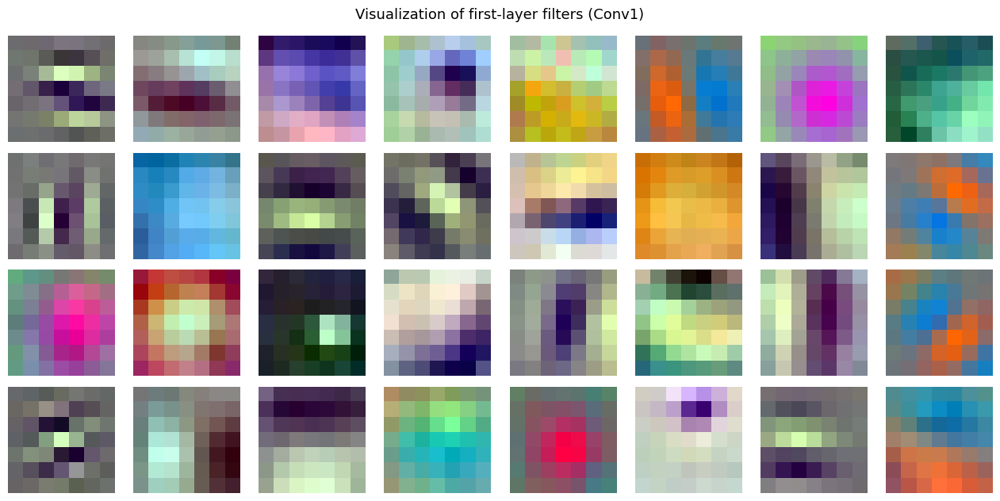

In [33]:
filters = model.conv1.weight.detach().cpu()
num_filters = 32
cols = 8
rows = num_filters // cols

plt.figure(figsize=(cols * 1.6, rows * 1.6))
for i in range(num_filters):
    f = filters[i]
    f = (f - f.min()) / (f.max() - f.min())  # normalize for display
    plt.subplot(rows, cols, i + 1)
    plt.imshow(f.permute(1,2,0))
    plt.axis("off")
plt.suptitle("Visualization of first-layer filters (Conv1)", fontsize=13)
plt.tight_layout()
plt.show()

> These filters are the *learned visual primitives* of a pretrained ResNet18 network trained on ImageNet.  
> Each colored square represents a $7 \times 7$ filter in the first convolutional layer that detects simple visual cues such as **edges, gradients, and color transitions**.  
>
> We can think of them as “reusable feature detectors” — building blocks that will later combine to detect complex textures, patterns, and objects.  
> This layer learns to identify **generic low-level features** that are not specific to any one dataset, which explains why pretrained CNNs often transfer well to new image domains.

**Visualizing pretrained filter responses on a real image**

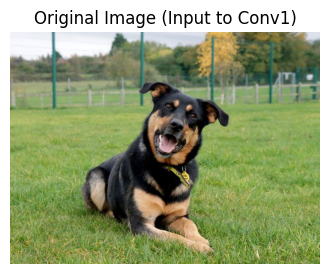

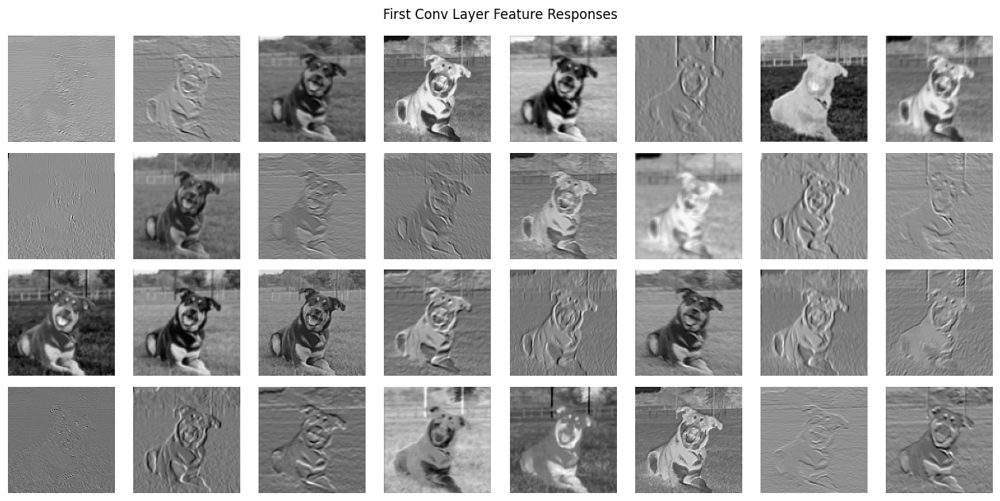

In [35]:
img = Image.open("/content/drive/MyDrive/dog.jpg")

plt.figure(figsize=(4,4))
plt.imshow(img)
plt.title("Original Image (Input to Conv1)")
plt.axis("off")
plt.show()

weights = models.ResNet18_Weights.IMAGENET1K_V1   # keep this reference for transforms
preprocess = weights.transforms()           # correct: use the transforms defined by weights
x = preprocess(img).unsqueeze(0)

with torch.no_grad():
    feat = model.conv1(x)[0]  # [C,H,W] feature maps


# Visualize a few feature responses ---
plt.figure(figsize=(cols * 1.6, rows * 1.6))
for i in range(num_filters):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(feat[i].cpu(), cmap="gray")
    plt.axis("off")

plt.suptitle("First Conv Layer Feature Responses", fontsize=12)
plt.tight_layout()
plt.show()

Each gray-scale map represents the *activation output* of one filter — essentially showing **which parts of the image strongly match that filter’s pattern**.  

> Notice how some filters activate around **edges** (e.g., the outline of the dog), while others capture **texture or brightness contrasts** (e.g., fur and background separation).  
> This illustrates how convolutional layers progressively build a hierarchical understanding of an image — starting from **edges and gradients** in early layers to **shapes and objects** in deeper ones.

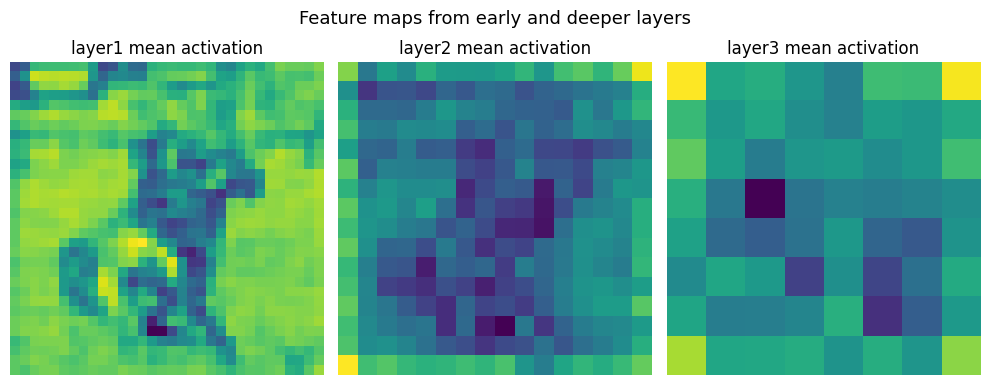

In [36]:
prep_tfm = transforms.Compose([
    transforms.Resize(128),
    transforms.CenterCrop(128),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

input_tensor = prep_tfm(img).unsqueeze(0).to(device)

# Define a hook to capture outputs of specific layers
feature_maps = {}

def get_activation(name):
    def hook(model, input, output):
        feature_maps[name] = output.detach().cpu()
    return hook

# Register hooks on two intermediate layers
model.layer1[0].conv1.register_forward_hook(get_activation("layer1"))
model.layer2[0].conv1.register_forward_hook(get_activation("layer2"))
model.layer3[0].conv1.register_forward_hook(get_activation("layer3"))

# Forward pass
with torch.no_grad():
    _ = model(input_tensor)

# Plot original image + selected feature maps
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
axes[0].imshow(img)
axes[0].set_title("Original image")
axes[0].axis("off")

display_order = ["layer1", "layer2", "layer3"]
for i, layer_name in enumerate(display_order, start=0):
    fmap = feature_maps[layer_name]
    fmap_mean = fmap[0].mean(dim=0)
    axes[i].imshow(fmap_mean, cmap="viridis")
    axes[i].set_title(f"{layer_name} mean activation")
    axes[i].axis("off")


plt.suptitle("Feature maps from early and deeper layers", fontsize=13)
plt.tight_layout()
plt.show()

> These visualizations show how convolutional layers transform the input image as it passes through the network.  
> Each map represents the **mean activation** across all feature channels for a specific layer — giving us a sense of how information evolves through the hierarchy.

**a. Early Layer (layer1)**  
- This layer captures **low-level visual patterns** such as edges, color transitions, and simple textures.  
- Notice the **sharp diagonal structure** resembling the outline of the dog — early filters focus on **local contrasts** and **edges**.  
- Activations here retain much of the **spatial detail** of the input image.

**b. Intermediate Layer (layer2)**  
- As we move deeper, the model starts combining multiple low-level features into **slightly more abstract patterns**.  
- The map looks more **blurred and coarser**, indicating that spatial details are being **compressed** while **semantic meaning increases**.  
- This layer may represent combinations like *fur texture*, *limb regions*, or *object boundaries*.

**c. Deeper Layer (layer3)**  
- The deepest map is much more **abstract** and **spatially coarse**.  
- The activations are concentrated in specific regions — the network is focusing on **high-level concepts** rather than edges or colors.  
- Such layers encode **object-level cues**, e.g., “dog presence,” “background context,” or “shape composition.”

**d. Hierarchical Insight**  
- CNNs transform the image from **pixels → edges → patterns → concepts**.  
- The gradual **loss of fine detail** and **increase in abstraction** mirrors how human vision works — early neurons detect edges, while deeper ones respond to objects.  
- Visualizing these feature maps helps us *see inside the black box*, revealing how convolutional layers progressively build up an understanding of the input.

**In short:**  
> - **Early layers** = "What am I looking at (edges, colors)?"  
> - **Middle layers** = "What patterns or parts are present?"  
> - **Deeper layers** = "What object or concept might this be?"


**Save Model and Metadata**

In [38]:
drive_path = "/content/drive/MyDrive"

save_dir = f"{drive_path}/checkpoints"
os.makedirs(save_dir, exist_ok=True)

checkpoint_path = os.path.join(save_dir, "resnet18_frozen_init.pth")
mapping_path = os.path.join(save_dir, "class_to_idx.pth")

# Save model state (untrained classifier + frozen backbone)
torch.save(model.state_dict(), checkpoint_path)

# Save class mapping
torch.save(train_dataset.class_to_idx, mapping_path)

print(f"[saved] Model checkpoint: {checkpoint_path}")
print(f"[saved] Class mapping: {mapping_path}")

[saved] Model checkpoint: /content/drive/MyDrive/checkpoints/resnet18_frozen_init.pth
[saved] Class mapping: /content/drive/MyDrive/checkpoints/class_to_idx.pth
